In [ ]:
import fitz  # PyMuPDF
import pandas as pd
import re
import numpy as np

# Open the PDF file
pdf_path = "toss_transactions.pdf"
pdf_document = fitz.open(pdf_path)

print(f"Total pages in PDF: {len(pdf_document)}")

# Let's examine the first page to understand the structure
first_page = pdf_document[0]
print(f"\nFirst page text preview:")
text = first_page.get_text()
print(text[:1000])  # First 1000 characters


In [ ]:
# # Let's try to extract tables using PyMuPDF's table detection
# # pdf_path = "toss_transactions.pdf"
# # pdf_document = fitz.open(pdf_path)
# # first_page = pdf_document[0]
# tables = first_page.find_tables()
# print(f"Number of tables found on first page: {len(tables)}")

# if tables:
#     for i, table in enumerate(tables):
#         print(f"\nTable {i+1}:")
#         print(f"Table bbox: {table.bbox}")
        
#         # Extract table data
#         table_data = table.extract()
#         print(f"Table dimensions: {len(table_data)} rows x {len(table_data[0]) if table_data else 0} columns")
        
#         # Show first few rows
#         for j, row in enumerate(table_data[:5]):
#             print(f"Row {j+1}: {row}")
        
#         if len(table_data) > 5:
#             print("...")
# else:
#     print("No tables detected automatically. Let's try text-based extraction.")


In [ ]:
# Extract all transaction data from all pages
all_transactions = []

for page_num in range(len(pdf_document)):
    page = pdf_document[page_num]
    
    # Find tables on this page
    table_finder = page.find_tables()
    tables = list(table_finder)
    
    for table in tables:
        table_data = table.extract()
        
        # Skip if not a transaction table (check if it has the expected columns)
        if len(table_data) > 0 and len(table_data[0]) >= 5:
            # Check if this looks like a transaction table
            header = table_data[0]
            if any(col and ('Date' in str(col) or 'Remarks' in str(col) or 'Amount' in str(col)) for col in header):
                # Skip header row and add all data rows
                for row in table_data[1:]:
                    if len(row) >= 5 and row[0]:  # Must have date and other data
                        all_transactions.append(row)

print(f"Total transactions extracted: {len(all_transactions)}")
print("Sample transactions:")
for i, transaction in enumerate(all_transactions[:10]):
    print(f"{i+1}: {transaction}")


In [ ]:
# Create a DataFrame from the transactions
df = pd.DataFrame(all_transactions, columns=['Date', 'Remarks', 'Transaction Amount', 'Balance', 'Notes'])

# Clean and process the data
def clean_date_and_time(date_str):
    """Extract date and time from date string"""
    if pd.isna(date_str) or date_str == '':
        return '', ''
    
    parts = str(date_str).split('\n')
    date_part = parts[0].strip() if len(parts) > 0 else ''
    time_part = parts[1].strip() if len(parts) > 1 else ''
    return date_part, time_part

def clean_amount(amount_str):
    """Clean amount string and preserve original signs (positive for deposits, negative for withdrawals)"""
    if pd.isna(amount_str) or amount_str == '':
        return ''
    
    # Remove commas and convert to float, then back to string
    cleaned = str(amount_str).replace(',', '').strip()
    try:
        num_val = float(cleaned)
        return str(num_val)  # Keep original sign (positive/negative)
    except:
        return str(amount_str)

def clean_notes(notes_str):
    """Clean notes - no quotes for all caps text"""
    if pd.isna(notes_str) or notes_str == '':
        return ''
    
    notes = str(notes_str).strip()
    return notes

# Apply cleaning functions
df[['Date', 'Time']] = df['Date'].apply(lambda x: pd.Series(clean_date_and_time(x)))
df['Transaction Amount'] = df['Transaction Amount'].apply(clean_amount)
df['Remarks'] = df['Remarks'].fillna('').astype(str)
df['Balance'] = df['Balance'].apply(clean_amount)
df['Notes'] = df['Notes'].apply(clean_notes)

# Filter out rows with invalid data (keep all valid transactions)
df = df[df['Date'] != ''].copy()

print(f"Cleaned transactions: {len(df)}")
print("\nSample cleaned data:")
print(df[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].head(10))


In [ ]:
# Sort transactions by date (newest first)
df = df.sort_values('Date', ascending=False)

print(f"Total transactions: {len(df)}")
print("\nTransaction data preview:")
print(df[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].head(10))


In [ ]:
# Prepare data for CSV export with proper column order
if 'Time' in df.columns and df['Time'].notna().any():
    # Include Time column if it has data
    export_df = df[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].copy()
else:
    # Export without Time column if no time data
    export_df = df[['Date', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].copy()

# Handle Notes column - no quotes for all caps text
def format_notes_for_csv(notes_str):
    if pd.isna(notes_str) or str(notes_str).strip() == '':
        return ''
    notes = str(notes_str).strip()
    # If all caps and contains only letters and spaces, don't quote
    if notes.isupper() and notes.replace(' ', '').isalpha():
        return notes
    return notes

export_df['Notes'] = export_df['Notes'].apply(format_notes_for_csv)

print("Transaction data for export (first 20 rows):")
print(export_df.head(20))

# Export to CSV with minimal quoting
csv_filename = 'toss_expense_analysis.csv'
export_df.to_csv(csv_filename, index=False, encoding='utf-8-sig', quoting=0)
print(f"\nTransaction data saved to: {csv_filename}")

print(f"\nTotal transactions exported: {len(export_df)}")
print(f"Columns: {list(export_df.columns)}")


In [ ]:
# Keep original signs in Transaction Amount column (positive for deposits, negative for withdrawals)
print("Transaction Amount column with preserved signs (first 10 rows):")
print(export_df[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Balance', 'Notes']].head(10))

# Export data with preserved signs to CSV
csv_filename = 'toss_expense_analysis.csv'
export_df.to_csv(csv_filename, index=False, encoding='utf-8-sig', quoting=0)
print(f"\nTransaction data with preserved signs saved to: {csv_filename}")
print(f"Total transactions exported: {len(export_df)}")


In [71]:
df = pd.read_csv('toss_expense_analysis.csv')

In [73]:
def notes_analysis(df, name):
    mask = df['Notes'].str.contains(name, na=False, case=False)
    total_spent = df.loc[mask, 'Transaction Amount'].sum()
    print(f"Total spent at {name}:", total_spent)

notes_analysis(df, '페이브')

Total spent at 페이브: -36000.0


In [75]:
notes_analysis(df, '카드 캐시백')

Total spent at 카드 캐시백: 4800.0


In [76]:
notes_analysis(df, '통장 이자')

Total spent at 통장 이자: 430.0


In [77]:
notes_analysis(df, '김용채')

Total spent at 김용채: -3587000.0


In [78]:
notes_analysis(df, '이마트24')

Total spent at 이마트24: -183400.0


In [79]:
notes_analysis(df, '스마일마트')

Total spent at 스마일마트: -199410.0


In [80]:
notes_analysis(df, '셔호나')

Total spent at 셔호나: -195400.0


In [81]:
notes_analysis(df, 'SENTBE')

Total spent at SENTBE: -75000.0


In [82]:
notes_analysis(df, '나우커피 인하대점')

Total spent at 나우커피 인하대점: -14000.0


In [84]:
notes_analysis(df, '건강TOSHNIYO')

Total spent at 건강TOSHNIYO: -629310.0


In [85]:
notes_analysis(df, 'TOSHNIYO')

Total spent at TOSHNIYO: -988942.0


In [69]:
def column_value_counts(df, name):
    print(df[name].value_counts())

In [ ]:
column_value_counts(df, 'Remarks')

In [ ]:
column_value_counts(df, 'Notes')

In [61]:
def individual_transactions(name):
    mask = df['Notes'].str.contains(name, na=False, case=False)
    kurbonalie_transactions = df.loc[mask]

    print(f'All {name} transactions:')
    print(kurbonalie_transactions[['Date', 'Time', 'Remarks', 'Transaction Amount', 'Notes']])

    # Calculate totals by Remarks type
    withdrawal_mask = mask & (df['Remarks'] == 'Withdrawal')
    deposit_mask = mask & (df['Remarks'] == 'Deposit')

    total_withdrawal = df.loc[withdrawal_mask, 'Transaction Amount'].sum()
    total_deposit = df.loc[deposit_mask, 'Transaction Amount'].sum()

    print(f'\n{name} Summary:')
    print(f'Withdrawals: {total_withdrawal} KRW ({withdrawal_mask.sum()} transactions)')
    print(f'Deposits: {total_deposit} KRW ({deposit_mask.sum()} transactions)')
    print(f'Net amount: {total_deposit - total_withdrawal} KRW')

In [ ]:
individual_transactions('ABDUKARIMOV HUMOYUNBEK')

In [ ]:
individual_transactions('KURBONALIE')

In [ ]:
individual_transactions('MUNTOXIROV')

In [ ]:
individual_transactions('NAJIMOV OTABEK')

In [87]:
individual_transactions('KIYOMOV')

All KIYOMOV transactions:
           Date      Time     Remarks  Transaction Amount  \
5    2025-09-09  22:49:56  Withdrawal           -250000.0   
8    2025-09-09  22:40:59  Withdrawal           -750000.0   
233  2025-07-07  20:25:49  Withdrawal           -201000.0   
234  2025-07-07  20:23:23     Deposit              1000.0   
330  2025-06-16  14:40:24  Withdrawal            -30000.0   
449  2025-05-21  21:50:05     Deposit            215938.0   
472  2025-05-02  18:00:53     Deposit              5000.0   
500  2025-04-21  22:36:07     Deposit            195000.0   

                             Notes  
5    KIYOMOV ASADBEK KOSIMJON UGLI  
8    KIYOMOV ASADBEK KOSIMJON UGLI  
233                     KIYOMOVASA  
234                      KIYOMOVAS  
330                     KIYOMOVASA  
449                      KIYOMOVAS  
472                      KIYOMOVAS  
500                      KIYOMOVAS  

KIYOMOV Summary:
Withdrawals: -1231000.0 KRW (4 transactions)
Deposits: 416938.0 KRW (4 tr

In [102]:
import pandas as pd
import numpy as np

# Read the CSV file
df = pd.read_csv('toss_expense_analysis.csv')
df['Date'] = pd.to_datetime(df['Date'])
# df['Transaction Amount'] = pd.to_numeric(df['Transaction Amount'])

# Categorize transactions as Income or Expenses
def categorize_cashflow(row):
    if row['Remarks'] in ['Deposit'] or row['Notes'] in ['ATM입금']:
        return 'Income'
    elif row['Remarks'] in ['Withdrawal', 'Check Card', 'Open\nBanking'] or row['Notes'] in ['ATM현금']:
        return 'Expenses'
    else:
        return 'Other'

df['CashFlow_Type'] = df.apply(categorize_cashflow, axis=1)

# Monthly cash flow analysis
df['Month'] = df['Date'].dt.to_period('M')
monthly_cashflow = df.groupby(['Month', 'CashFlow_Type'])['Transaction Amount'].sum().unstack(fill_value=0)

print('=== MONTHLY CASH FLOW ANALYSIS ===')
print(monthly_cashflow)

# Calculate net cash flow
monthly_cashflow['Net_Flow'] = monthly_cashflow['Income'] - monthly_cashflow['Expenses']
print('\n=== NET CASH FLOW BY MONTH ===')
print(monthly_cashflow['Net_Flow'])

# Overall totals
total_income = df[df['CashFlow_Type'] == 'Income']['Transaction Amount'].sum()
total_expenses = df[df['CashFlow_Type'] == 'Expenses']['Transaction Amount'].sum()
net_total = total_income - total_expenses

print(f'\n=== OVERALL CASH FLOW SUMMARY ===')
print(f'Total Income: {total_income:,.0f} KRW')
print(f'Total Expenses: {total_expenses:,.0f} KRW')
print(f'Net Cash Flow: {net_total:,.0f} KRW')
print(f'Savings Rate: {(net_total/total_income)*100:.1f}%')

=== MONTHLY CASH FLOW ANALYSIS ===
CashFlow_Type   Expenses     Income   Other
Month                                      
2025-04        -885350.0   886148.0   200.0
2025-05        -946302.0  1090470.0   329.0
2025-06       -3346055.0  3319500.0  1238.0
2025-07       -4035618.0  4369807.0  1169.0
2025-08       -2556904.0  2152922.0  1968.0
2025-09       -1282048.0  1228300.0   326.0

=== NET CASH FLOW BY MONTH ===
Month
2025-04    1771498.0
2025-05    2036772.0
2025-06    6665555.0
2025-07    8405425.0
2025-08    4709826.0
2025-09    2510348.0
Freq: M, Name: Net_Flow, dtype: float64

=== OVERALL CASH FLOW SUMMARY ===
Total Income: 13,047,147 KRW
Total Expenses: -13,052,277 KRW
Net Cash Flow: 26,099,424 KRW
Savings Rate: 200.0%


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set style for better looking plots
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

# Read and prepare data
df = pd.read_csv('toss_expense_analysis.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['Transaction Amount'] = pd.to_numeric(df['Transaction Amount'])

# Categorize transactions
def categorize_cashflow(row):
    if row['Remarks'] in ['Deposit'] or row['Notes'] in ['ATM입금']:
        return 'Income'
    elif row['Remarks'] in ['Withdrawal', 'Check Card', 'Open\nBanking'] or row['Notes'] in ['ATM현금']:
        return 'Expenses'
    else:
        return 'Other'

df['CashFlow_Type'] = df.apply(categorize_cashflow, axis=1)
df['Month'] = df['Date'].dt.to_period('M')

# Monthly cash flow
monthly_cashflow = df.groupby(['Month', 'CashFlow_Type'])['Transaction Amount'].sum().unstack(fill_value=0)
monthly_cashflow['Net_Flow'] = monthly_cashflow['Income'] - monthly_cashflow['Expenses']

# Create visualizations
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('💰 CASH FLOW ANALYSIS - MURTAZO TOSHNIYOZOV', fontsize=18, fontweight='bold', y=0.98)

# 1. Monthly Income vs Expenses (Line Chart)
months = [str(m) for m in monthly_cashflow.index]
ax1.plot(months, monthly_cashflow['Income'], marker='o', linewidth=3, markersize=8, label='Income', color='#2E8B57')
ax1.plot(months, monthly_cashflow['Expenses'], marker='s', linewidth=3, markersize=8, label='Expenses', color='#DC143C')
ax1.set_title('📈 Monthly Income vs Expenses Trend', fontsize=14, fontweight='bold', pad=20)
ax1.set_ylabel('Amount (KRW)', fontsize=12)
ax1.legend(fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='x', rotation=45, labelsize=10)

# Format y-axis to show values in millions
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000000:.1f}M'))

# 2. Net Cash Flow by Month (Bar Chart)
colors = ['#2E8B57' if x >= 0 else '#DC143C' for x in monthly_cashflow['Net_Flow']]
bars = ax2.bar(months, monthly_cashflow['Net_Flow'], color=colors, alpha=0.8, edgecolor='black', linewidth=1)
ax2.set_title('📊 Monthly Net Cash Flow', fontsize=14, fontweight='bold', pad=20)
ax2.set_ylabel('Net Amount (KRW)', fontsize=12)
ax2.axhline(y=0, color='black', linestyle='-', alpha=0.5, linewidth=2)
ax2.tick_params(axis='x', rotation=45, labelsize=10)

# Add value labels on bars
for bar, value in zip(bars, monthly_cashflow['Net_Flow']):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + (50000 if height >= 0 else -50000),
             f'{value:,.0f}', ha='center', va='bottom' if height >= 0 else 'top', fontsize=10, fontweight='bold')

# 3. Overall Income vs Expenses (Pie Chart)
total_income = df[df['CashFlow_Type'] == 'Income']['Transaction Amount'].sum()
total_expenses = (df[df['CashFlow_Type'] == 'Expenses']['Transaction Amount'].sum()) * -1

wedges, texts, autotexts = ax3.pie([total_income, total_expenses], 
                                  labels=['Income', 'Expenses'], 
                                  colors=['#2E8B57', '#DC143C'],
                                  autopct='%1.1f%%',
                                  startangle=90,
                                  explode=(0.05, 0.05),
                                  shadow=True)

ax3.set_title('🥧 Overall Income vs Expenses Distribution', fontsize=14, fontweight='bold', pad=20)

# Make percentage text bold
for autotext in autotexts:
    autotext.set_fontweight('bold')
    autotext.set_fontsize(12)

# 4. Monthly Summary Table
ax4.axis('off')
monthly_summary = monthly_cashflow[['Income', 'Expenses', 'Net_Flow']].copy()
monthly_summary.columns = ['Income', 'Expenses', 'Net Flow']

# Create table data
table_data = []
for month in monthly_summary.index:
    row = [str(month)]
    row.extend([f'{val:,.0f}' for val in monthly_summary.loc[month]])
    table_data.append(row)

table = ax4.table(cellText=table_data,
                 colLabels=['Month', 'Income (KRW)', 'Expenses (KRW)', 'Net Flow (KRW)'],
                 cellLoc='center',
                 loc='center',
                 bbox=[0, 0, 1, 1])

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

# Style the table
for i in range(len(table_data) + 1):
    for j in range(4):
        cell = table[(i, j)]
        if i == 0:  # Header row
            cell.set_facecolor('#4CAF50')
            cell.set_text_props(weight='bold', color='white')
        else:
            cell.set_facecolor('#F5F5F5' if i % 2 == 0 else 'white')

ax4.set_title('📋 Monthly Cash Flow Summary', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('cash_flow_analysis.png', dpi=300, bbox_inches='tight', facecolor='white')
print('✅ Cash Flow Analysis visualization saved as cash_flow_analysis.png')

# Print summary statistics
print('\n=== CASH FLOW SUMMARY ===')
print(f'Total Income: {total_income:,.0f} KRW')
print(f'Total Expenses: {total_expenses:,.0f} KRW')
print(f'Net Cash Flow: {total_income - total_expenses:,.0f} KRW')
print(f'Savings Rate: {((total_income - total_expenses)/total_income)*100:.1f}%')

✅ Simple Cash Flow Pie Chart saved as cash_flow_pie_chart.png
✅ Monthly Cash Flow Pie Charts saved as monthly_cash_flow_pie_charts.png


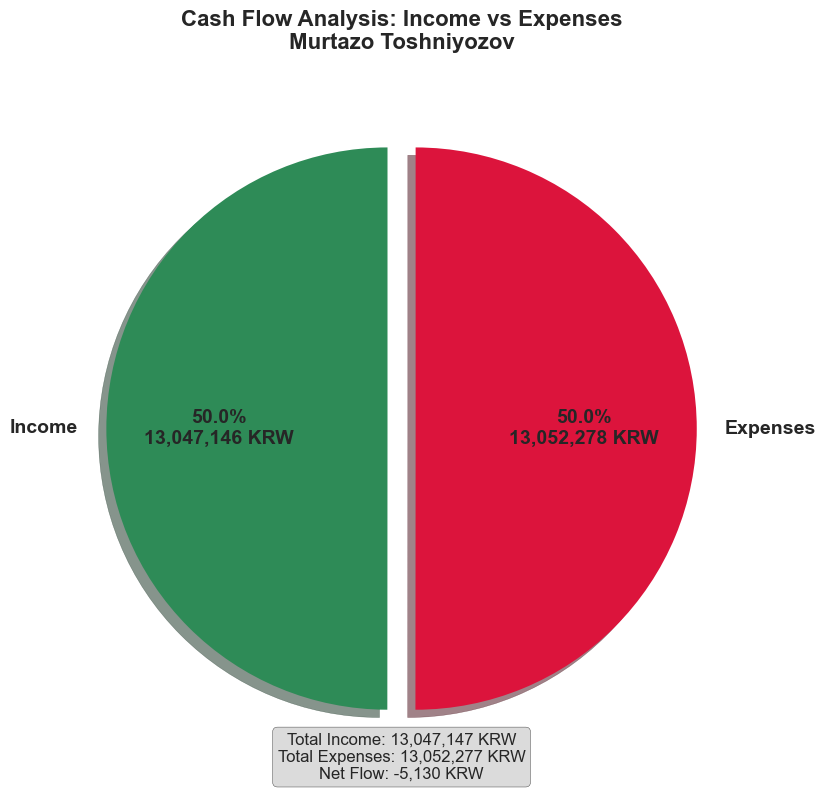

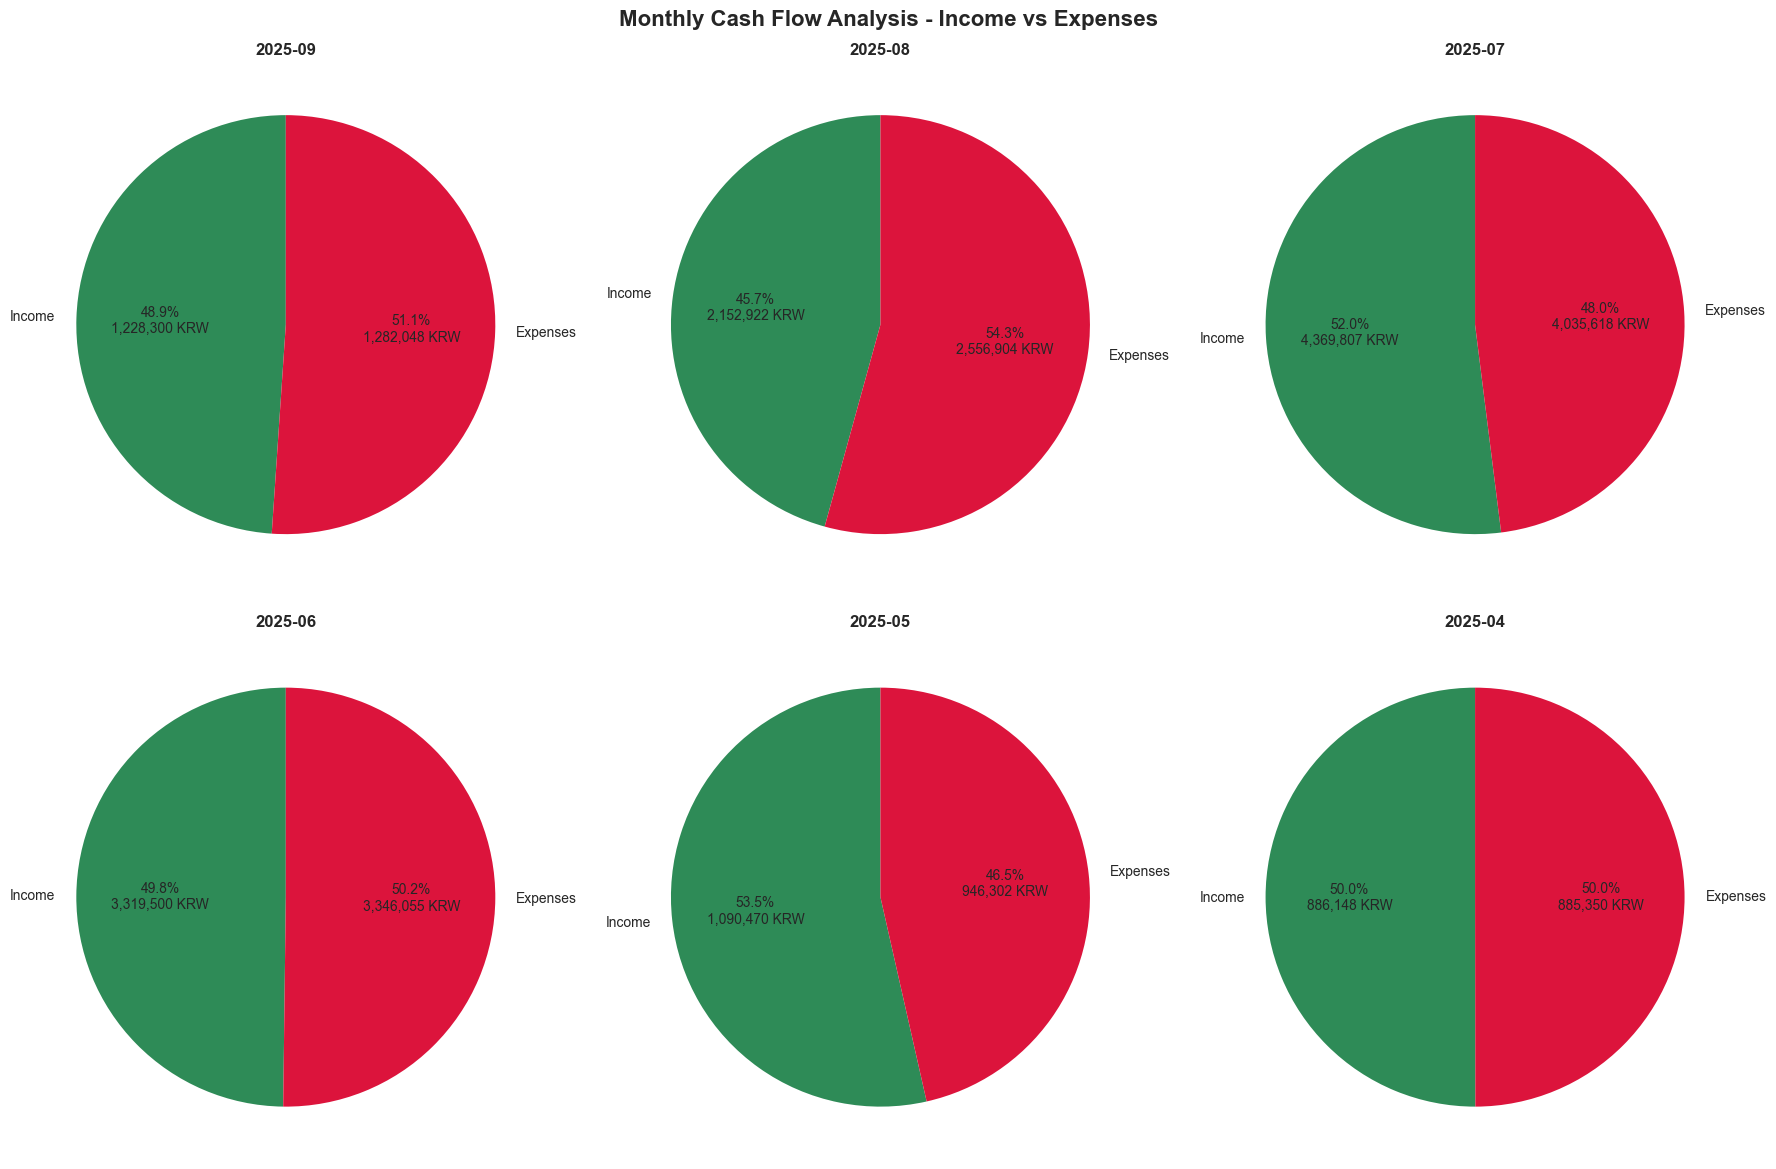

In [106]:
import pandas as pd
import matplotlib.pyplot as plt

# Read and prepare data
df = pd.read_csv('toss_expense_analysis.csv')


# Categorize transactions
def categorize_cashflow(row):
    if row['Remarks'] in ['Deposit'] or row['Notes'] in ['ATM입금']:
        return 'Income'
    elif row['Remarks'] in ['Withdrawal', 'Check Card', 'Open\nBanking'] or row['Notes'] in ['ATM현금']:
        return 'Expenses'
    else:
        return 'Other'

df['CashFlow_Type'] = df.apply(categorize_cashflow, axis=1)

def autopct_format(values):
    def inner_autopct(pct):
        total = sum(values)
        val = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n{val:,.0f} KRW"
    return inner_autopct


# Calculate totals
total_income = df[df['CashFlow_Type'] == 'Income']['Transaction Amount'].sum()
total_expenses = (df[df['CashFlow_Type'] == 'Expenses']['Transaction Amount'].sum()) * -1

net_flow = total_income - total_expenses

# Create a simple pie chart
plt.figure(figsize=(10, 8))

# Data for pie chart
labels = ['Income', 'Expenses']
sizes = [total_income, total_expenses]
colors = ['#2E8B57', '#DC143C']  # Green for income, Red for expenses
explode = (0.05, 0.05)  # Separate the slices

# Create pie chart
wedges, texts, autotexts = plt.pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct=autopct_format(sizes),  # 👈 custom formatter
    startangle=90,
    explode=explode,
    shadow=True,
    textprops={'fontsize': 14, 'fontweight': 'bold'}
)

# Add title
plt.title('Cash Flow Analysis: Income vs Expenses\nMurtazo Toshniyozov', 
          fontsize=16, fontweight='bold', pad=20)

# Add summary text
summary_text = f'Total Income: {total_income:,.0f} KRW\nTotal Expenses: {total_expenses:,.0f} KRW\nNet Flow: {net_flow:,.0f} KRW'
plt.figtext(0.5, 0.02, summary_text, ha='center', fontsize=12, 
            bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.8))

plt.tight_layout()
plt.savefig('cash_flow_pie_chart.png', dpi=300, bbox_inches='tight', facecolor='white')
print('✅ Simple Cash Flow Pie Chart saved as cash_flow_pie_chart.png')

# Also create monthly pie charts
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M')

# Create subplot for monthly pie charts
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Monthly Cash Flow Analysis - Income vs Expenses', fontsize=16, fontweight='bold')

months = df['Month'].unique()
axes = axes.flatten()

for i, month in enumerate(months):
    if i < 6:  # Only show first 6 months
        month_data = df[df['Month'] == month]
        month_income = month_data[month_data['CashFlow_Type'] == 'Income']['Transaction Amount'].sum()
        month_expenses = (month_data[month_data['CashFlow_Type'] == 'Expenses']['Transaction Amount'].sum()) * -1
        
        if month_income > 0 or month_expenses > 0:
            sizes = [month_income, month_expenses]
            labels = ['Income', 'Expenses']
            colors = ['#2E8B57', '#DC143C']
            
            axes[i].pie(sizes, labels=labels, colors=colors, autopct=autopct_format(sizes), startangle=90)
            axes[i].set_title(f'{month}', fontweight='bold')
        else:
            axes[i].text(0.5, 0.5, 'No Data', ha='center', va='center', transform=axes[i].transAxes)
            axes[i].set_title(f'{month}', fontweight='bold')

# Hide unused subplots
for i in range(len(months), 6):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig('monthly_cash_flow_pie_charts.png', dpi=300, bbox_inches='tight', facecolor='white')
print('✅ Monthly Cash Flow Pie Charts saved as monthly_cash_flow_pie_charts.png')